### ============================================================
### PRACTICAL 4
### NON-NEGATIVE MATRIX FACTORIZATION FOR TOP-N RECOMMENDATION
### Dataset: MovieLens Small
### ============================================================

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
DATA_FOLDER = "/content/drive/MyDrive/mlsmall"
RATINGS_FILE = DATA_FOLDER + "/ratings.csv"
MOVIES_FILE = DATA_FOLDER + "/movies.csv"

N_FACTORS = 10
N_ITERATIONS = 100
EPSILON = 1e-8
TOP_N = 10
RANKING_K = 10
RELEVANCE_THRESHOLD = 4.0
DEMO_USER_ID = 25
TOP_MOVIES_PER_FACTOR = 10
RANDOM_STATE = 19

In [4]:
# Load data
ratings = pd.read_csv(RATINGS_FILE)
movies = pd.read_csv(MOVIES_FILE)

print("=" * 70)
print("MOVIELENS DATASET")
print("=" * 70)
print("Ratings shape:", ratings.shape)
print("Movies shape :", movies.shape)

display(ratings.head())
display(movies.head())

MOVIELENS DATASET
Ratings shape: (100836, 4)
Movies shape : (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
required_rating_columns = {"userId", "movieId", "rating", "timestamp"}
required_movie_columns = {"movieId", "title", "genres"}

if not required_rating_columns.issubset(ratings.columns): raise ValueError("ratings.csv must contain userId, movieId, rating and timestamp.")
if not required_movie_columns.issubset(movies.columns): raise ValueError("movies.csv must contain movieId, title and genres.")

print("Users :", ratings["userId"].nunique())
print("Movies:", ratings["movieId"].nunique())
print("Ratings:", len(ratings))

Users : 610
Movies: 9724
Ratings: 100836


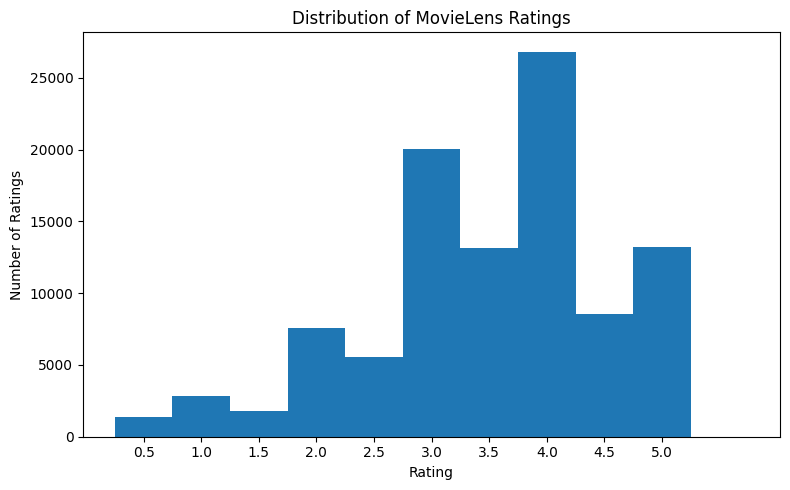

In [6]:
# 5. Visualize rating distribution
plt.figure(figsize=(8, 5))
plt.hist(ratings["rating"], bins=np.arange(0.25, 5.76, 0.5))
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Distribution of MovieLens Ratings")
plt.xticks(np.arange(0.5, 5.1, 0.5))
plt.tight_layout()
plt.show()

In [7]:
# 6. Chronological train-test split
ratings_sorted = ratings.sort_values(["userId", "timestamp"]).copy()
test_indices = (ratings_sorted.groupby("userId")["timestamp"].idxmax())

test_data = ratings_sorted.loc[test_indices].copy()
train_data = ratings_sorted.drop(index=test_indices).copy()

print("\nTraining ratings:", len(train_data))
print("Testing ratings :", len(test_data))


Training ratings: 100226
Testing ratings : 610


In [8]:
# 7. Create user-item matrix
train_matrix = train_data.pivot_table(index="userId", columns="movieId", values="rating")

movie_info = (movies.drop_duplicates("movieId").set_index("movieId")[["title", "genres"]])

print("\nUser-item matrix shape:", train_matrix.shape)
display(train_matrix.iloc[:8, :10])


User-item matrix shape: (610, 9702)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,3.0,5.0,4.0,4.0,3.0,NaN,3.0
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0


In [9]:
# 8. Sparsity
observed_count = int(train_matrix.notna().sum().sum())
total_cells = train_matrix.shape[0] * train_matrix.shape[1]
density = observed_count / total_cells
sparsity = 1.0 - density

print(f"\nMatrix density : {density * 100:.2f}%")
print(f"Matrix sparsity: {sparsity * 100:.2f}%")


Matrix density : 1.69%
Matrix sparsity: 98.31%


In [10]:
# 9. Build rating matrix R and observation mask M
# Missing ratings are stored as 0 in R, but M ensures that
# they do not contribute to the NMF training loss.
R = train_matrix.fillna(0).to_numpy(dtype=np.float64)
M = train_matrix.notna().astype(np.float64).to_numpy()

print("R shape:", R.shape)
print("M shape:", M.shape)

R shape: (610, 9702)
M shape: (610, 9702)


In [11]:
# 10. Manual masked NMF
def manual_masked_nmf(R, M, n_factors=10, n_iterations=100, epsilon=1e-8, random_state=RANDOM_STATE):
    """ Factorize R approximately as W @ H using multiplicative updates. The mask M makes training use only observed ratings. """

    rng = np.random.default_rng(RANDOM_STATE)
    n_users, n_movies = R.shape

    # Positive initialization keeps W and H non-negative.
    W = rng.random((n_users, n_factors)) + 0.1
    H = rng.random((n_factors, n_movies)) + 0.1

    observed_R = M * R
    observed_ratings = R[M == 1]

    if len(observed_ratings) == 0: raise ValueError("No observed ratings are available.")

    history = []

    for iteration in range(1, n_iterations + 1):

        # Update H
        WH = W @ H

        numerator_H = W.T @ observed_R
        denominator_H = W.T @ (M * WH) + epsilon

        H *= numerator_H / denominator_H
        H = np.maximum(H, epsilon)

        # Update W
        WH = W @ H

        numerator_W = observed_R @ H.T
        denominator_W = (M * WH) @ H.T + epsilon

        W *= numerator_W / denominator_W
        W = np.maximum(W, epsilon)

        # Error on observed ratings only
        WH = W @ H
        observed_prediction = WH[M == 1]

        observed_rmse = np.sqrt(np.mean((observed_ratings - observed_prediction) ** 2))

        history.append(observed_rmse)

        if iteration == 1 or iteration % 10 == 0 or iteration == n_iterations:
            print(f"Iteration {iteration:3d} | " f"Observed RMSE = {observed_rmse:.6f}")

    return W, H, history

In [12]:
# 11. Train the model
print("\n" + "=" * 70)
print("TRAINING MANUAL MASKED NMF")
print("=" * 70)

W, H, training_history = manual_masked_nmf(R=R, M=M, n_factors=N_FACTORS, n_iterations=N_ITERATIONS, epsilon=EPSILON, random_state=RANDOM_STATE)

print("W shape:", W.shape)
print("H shape:", H.shape)


TRAINING MANUAL MASKED NMF
Iteration   1 | Observed RMSE = 0.840767
Iteration  10 | Observed RMSE = 0.749110
Iteration  20 | Observed RMSE = 0.707989
Iteration  30 | Observed RMSE = 0.677975
Iteration  40 | Observed RMSE = 0.654752
Iteration  50 | Observed RMSE = 0.636576
Iteration  60 | Observed RMSE = 0.622305
Iteration  70 | Observed RMSE = 0.611016
Iteration  80 | Observed RMSE = 0.601944
Iteration  90 | Observed RMSE = 0.594509
Iteration 100 | Observed RMSE = 0.588300
W shape: (610, 10)
H shape: (10, 9702)


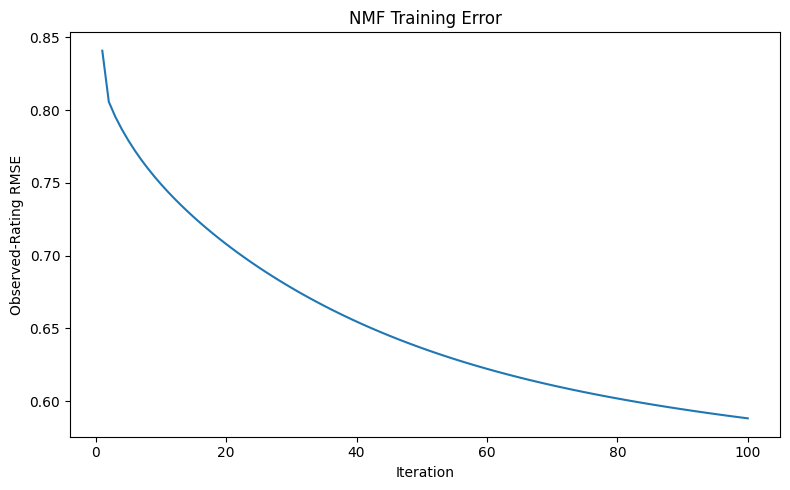

In [13]:
# 12. Plot training error
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(training_history) + 1), training_history)
plt.xlabel("Iteration")
plt.ylabel("Observed-Rating RMSE")
plt.title("NMF Training Error")
plt.tight_layout()
plt.show()

In [14]:
# 13. Reconstruct prediction matrix
prediction_values = W @ H
prediction_values = np.clip(prediction_values, 0.5, 5.0)

prediction_matrix = pd.DataFrame(prediction_values, index=train_matrix.index, columns=train_matrix.columns)

print("\nPredicted rating matrix sample")
display(prediction_matrix.iloc[:8, :10])


Predicted rating matrix sample


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.711192,4.315744,3.944490,2.768043,3.362894,4.616893,4.017389,3.524367,2.586536,3.817983
2,3.742460,3.208333,3.521525,2.140018,2.665865,3.388966,2.893758,1.624983,4.413737,3.254063
3,1.537763,2.430088,0.793089,1.035893,0.884929,1.881366,0.600580,1.679420,1.252075,1.791076
4,3.414342,2.585802,2.809412,3.666615,2.881196,3.427560,1.467561,3.401779,3.261890,3.136435
5,3.470396,3.599448,2.818976,3.275039,2.308835,3.978475,3.384114,1.648874,2.029090,3.467077
6,4.147302,4.264188,3.331514,3.163566,3.401826,4.105060,2.891660,2.876341,3.106445,3.937901
7,4.098803,4.043131,2.675095,1.563344,3.470947,4.214482,3.882480,4.113314,1.538882,3.583626
8,3.887598,3.510260,3.681216,3.057956,2.634991,3.871967,3.375917,2.487892,2.417014,3.137369


In [ ]:
# 14. Predict one rating
def predict_rating(user_id, movie_id):

    if user_id not in prediction_matrix.index: return np.nan

    if movie_id not in prediction_matrix.columns: return np.nan

    return float(prediction_matrix.loc[user_id, movie_id])

# 15. Evaluate rating prediction
test_rows = []

for row in test_data.itertuples():

    prediction = predict_rating(row.userId, row.movieId)

    if pd.notna(prediction):

        title = (movie_info.loc[row.movieId, "title"] if row.movieId in movie_info.index else str(row.movieId))

        test_rows.append({
            "userId": row.userId,
            "movieId": row.movieId,
            "Movie": title,
            "Actual Rating": row.rating,
            "Predicted Rating": prediction,
            "Absolute Error": abs(row.rating - prediction)
        })

test_predictions = pd.DataFrame(test_rows)

test_coverage = len(test_predictions) / len(test_data)

if len(test_predictions) > 0:

    test_mae = mean_absolute_error(
        test_predictions["Actual Rating"],
        test_predictions["Predicted Rating"]
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            test_predictions["Actual Rating"],
            test_predictions["Predicted Rating"]
        )
    )

else:
    test_mae = np.nan
    test_rmse = np.nan

print("\n" + "=" * 70)
print("RATING-PREDICTION EVALUATION")
print("=" * 70)

print("Test MAE :", round(test_mae, 4))
print("Test RMSE:", round(test_rmse, 4))
print("Prediction Coverage:", f"{test_coverage * 100:.2f}%")

display(test_predictions.head(15))


RATING-PREDICTION EVALUATION
Test MAE : 0.8341
Test RMSE: 1.0971
Prediction Coverage: 96.39%


,userId,movieId,Movie,Actual Rating,Predicted Rating,Absolute Error
0,1,2492,20 Dates (1998),4.0,3.498005,0.501995
1,2,80489,"Town, The (2010)",4.5,3.241699,1.258301
2,3,2424,You've Got Mail (1998),0.5,1.962422,1.462422
3,4,4246,Bridget Jones's Diary (2001),4.0,3.618493,0.381507
4,5,247,Heavenly Creatures (1994),5.0,3.997527,1.002473
5,6,780,Independence Day (a.k.a. ID4) (1996),5.0,4.393689,0.606311
6,7,49286,"Holiday, The (2006)",0.5,2.961366,2.461366
7,8,141,"Birdcage, The (1996)",3.0,3.697383,0.697383
8,10,1088,Dirty Dancing (1987),3.0,3.337908,0.337908
9,11,368,Maverick (1994),3.0,3.988191,0.988191


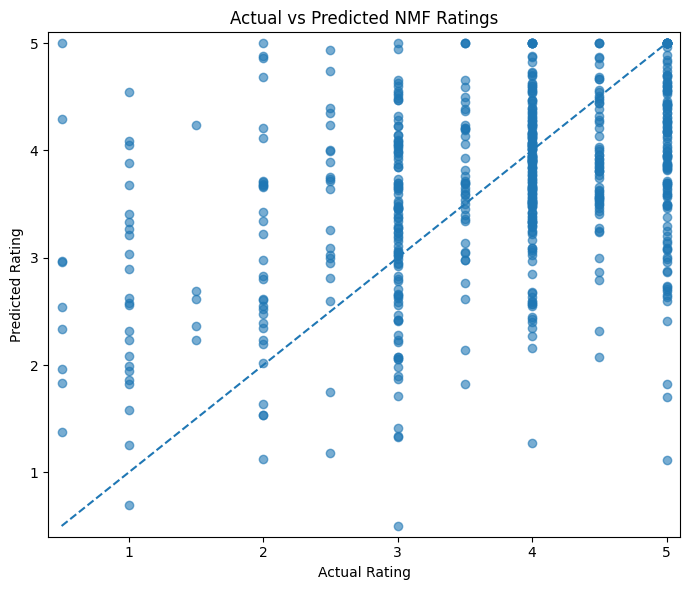

In [ ]:
# 16. Actual vs predicted visualization
if len(test_predictions) > 0:
    plt.figure(figsize=(7, 6))
    plt.scatter(test_predictions["Actual Rating"], test_predictions["Predicted Rating"], alpha=0.6)

    plt.plot([0.5, 5.0], [0.5, 5.0], linestyle="--")

    plt.xlabel("Actual Rating")
    plt.ylabel("Predicted Rating")
    plt.title("Actual vs Predicted NMF Ratings")

    plt.xlim(0.4, 5.1)
    plt.ylim(0.4, 5.1)

    plt.tight_layout()
    plt.show()

In [18]:
# 17. Top-N recommendation function
def recommend_movies(user_id, top_n=TOP_N):

    if user_id not in prediction_matrix.index: return pd.DataFrame()

    user_scores = prediction_matrix.loc[user_id].copy()

    seen_movies = (train_matrix.loc[user_id].dropna().index)

    user_scores = user_scores.drop(index=seen_movies, errors="ignore")

    top_scores = (user_scores.sort_values(ascending=False).head(top_n))

    result = pd.DataFrame({"movieId": top_scores.index, "Predicted Rating": top_scores.values})

    result["Movie"] = [movie_info.loc[mid, "title"] if mid in movie_info.index else str(mid) for mid in result["movieId"]]

    result["Genres"] = [movie_info.loc[mid, "genres"] if mid in movie_info.index else "" for mid in result["movieId"]]

    return result[["movieId", "Movie", "Genres", "Predicted Rating"]]

# 18. Show Top-N recommendations
recommendations = recommend_movies(DEMO_USER_ID, top_n=TOP_N)

print("\n" + "=" * 70)
print(f"TOP {TOP_N} NMF RECOMMENDATIONS FOR USER {DEMO_USER_ID}")
print("=" * 70)

display(recommendations)


TOP 10 NMF RECOMMENDATIONS FOR USER 25


,movieId,Movie,Genres,Predicted Rating
0,16,Casino (1995),Crime|Drama,5.0
1,193609,Andrew Dice Clay: Dice Rules (1991),Comedy,5.0
2,190183,The Darkest Minds (2018),Sci-Fi|Thriller,5.0
3,5646,Valmont (1989),Drama|Romance,5.0
4,5500,Top Secret! (1984),Comedy,5.0
5,5513,Martin Lawrence Live: Runteldat (2002),Comedy|Documentary,5.0
6,5515,Songs From the Second Floor (Sånger från andra...,Drama,5.0
7,5685,Real Women Have Curves (2002),Comedy|Drama,5.0
8,183317,Patti Rocks (1988),Comedy|Drama,5.0
9,183897,Isle of Dogs (2018),Animation|Comedy,5.0


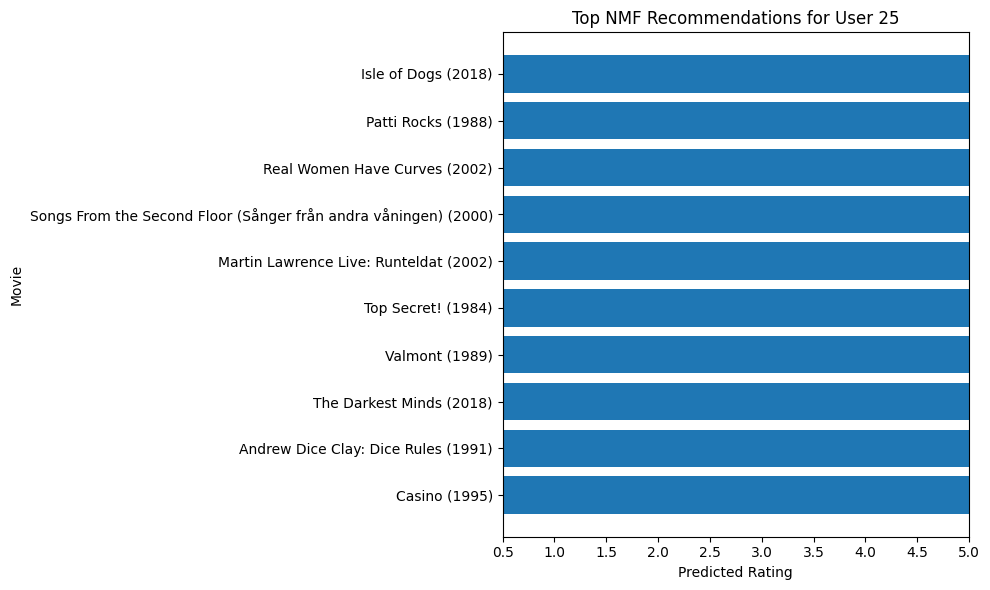

In [19]:
# 19. Plot Top-N recommendations
if not recommendations.empty:

    plot_data = recommendations.sort_values("Predicted Rating", ascending=True)

    plt.figure(figsize=(10, 6))

    plt.barh(plot_data["Movie"], plot_data["Predicted Rating"])

    plt.xlabel("Predicted Rating")
    plt.ylabel("Movie")
    plt.title(f"Top NMF Recommendations for User {DEMO_USER_ID}")
    plt.xlim(0.5, 5.0)

    plt.tight_layout()
    plt.show()

In [ ]:
# 20. Ranking evaluation
ranking_rows = []

for row in test_data.itertuples():

    if row.rating < RELEVANCE_THRESHOLD:
        continue

    user_id = row.userId
    target_movie = row.movieId

    if user_id not in prediction_matrix.index:
        continue

    if target_movie not in prediction_matrix.columns:
        continue

    scores = prediction_matrix.loc[user_id].copy()

    seen_movies = train_matrix.loc[user_id].dropna().index

    scores = scores.drop(
        index=seen_movies,
        errors="ignore"
    )

    ranked_movies = (
        scores
        .sort_values(ascending=False)
        .index
        .tolist()
    )

    try:
        rank = ranked_movies.index(target_movie) + 1
    except ValueError:
        rank = None

    hit = int(
        rank is not None
        and rank <= RANKING_K
    )

    rr = (
        1.0 / rank
        if rank is not None and rank <= RANKING_K
        else 0.0
    )

    ndcg = (
        1.0 / np.log2(rank + 1)
        if rank is not None and rank <= RANKING_K
        else 0.0
    )

    ranking_rows.append({
        "userId": user_id,
        "movieId": target_movie,
        "Target Rating": row.rating,
        "Target Rank": rank,
        f"Hit@{RANKING_K}": hit,
        f"RR@{RANKING_K}": rr,
        f"NDCG@{RANKING_K}": ndcg
    })

ranking_results = pd.DataFrame(ranking_rows)

if len(ranking_results) > 0:

    hit_rate = ranking_results[f"Hit@{RANKING_K}"].mean()
    mrr_at_k = ranking_results[f"RR@{RANKING_K}"].mean()
    ndcg_at_k = ranking_results[f"NDCG@{RANKING_K}"].mean()

else:

    hit_rate = np.nan
    mrr_at_k = np.nan
    ndcg_at_k = np.nan

print("\n" + "=" * 70)
print("TOP-K RANKING EVALUATION")
print("=" * 70)

print(f"Hit Rate@{RANKING_K}:", round(hit_rate, 4))
print(f"MRR@{RANKING_K}:", round(mrr_at_k, 4))
print(f"NDCG@{RANKING_K}:", round(ndcg_at_k, 4))

# 21. User latent-factor table
user_ids = train_matrix.index.to_numpy()

user_to_position = {
    user_id: position
    for position, user_id in enumerate(user_ids)
}

factor_names = [
    f"Factor {i + 1}"
    for i in range(N_FACTORS)
]

if DEMO_USER_ID in user_to_position:

    user_position = user_to_position[DEMO_USER_ID]

    demo_user_factors = pd.DataFrame({
        "Latent Factor": factor_names,
        "User Weight": W[user_position]
    })

    demo_user_factors = (
        demo_user_factors
        .sort_values(
            "User Weight",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\n" + "=" * 70)
    print(f"LATENT FACTORS FOR USER {DEMO_USER_ID}")
    print("=" * 70)

    display(demo_user_factors)

# 22. Visualize selected user's latent factors
if DEMO_USER_ID in user_to_position:

    plot_user_factors = demo_user_factors.sort_values(
        "User Weight",
        ascending=True
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        plot_user_factors["Latent Factor"],
        plot_user_factors["User Weight"]
    )

    plt.xlabel("User Weight")
    plt.ylabel("Latent Factor")
    plt.title(f"NMF Latent Factors for User {DEMO_USER_ID}")

    plt.tight_layout()
    plt.show()

# 23. Top movies for each latent factor
movie_ids = train_matrix.columns.to_numpy()

def top_movies_for_factor(
    factor_index,
    top_n=TOP_MOVIES_PER_FACTOR
):

    if not 0 <= factor_index < N_FACTORS:
        raise ValueError(
            f"factor_index must be between 0 and {N_FACTORS - 1}."
        )

    weights = H[factor_index]

    order = np.argsort(
        weights
    )[::-1][:top_n]

    rows = []

    for position in order:

        movie_id = movie_ids[position]

        title = (
            movie_info.loc[movie_id, "title"]
            if movie_id in movie_info.index
            else str(movie_id)
        )

        genres = (
            movie_info.loc[movie_id, "genres"]
            if movie_id in movie_info.index
            else ""
        )

        rows.append({
            "Factor": factor_index + 1,
            "movieId": movie_id,
            "Movie": title,
            "Genres": genres,
            "Factor Weight": weights[position]
        })

    return pd.DataFrame(rows)

all_factor_tables = []

for factor_index in range(N_FACTORS):

    factor_table = top_movies_for_factor(
        factor_index,
        top_n=TOP_MOVIES_PER_FACTOR
    )

    all_factor_tables.append(factor_table)

    print("\n" + "=" * 70)
    print(f"TOP MOVIES FOR LATENT FACTOR {factor_index + 1}")
    print("=" * 70)

    display(factor_table)

latent_factor_movies = pd.concat(
    all_factor_tables,
    ignore_index=True
)

# 24. Genre summary for each latent factor
genre_rows = []

for factor_number in range(1, N_FACTORS + 1):

    factor_movies = latent_factor_movies[
        latent_factor_movies["Factor"] == factor_number
    ]

    genre_counts = {}

    for genre_text in factor_movies["Genres"].dropna():

        for genre in genre_text.split("|"):

            if genre == "(no genres listed)":
                continue

            genre_counts[genre] = genre_counts.get(genre, 0) + 1

    top_genres = sorted(
        genre_counts.items(),
        key=lambda item: item[1],
        reverse=True
    )[:5]

    genre_rows.append({
        "Factor": factor_number,
        "Frequent Genres in Top Movies": ", ".join(
            [
                f"{genre} ({count})"
                for genre, count in top_genres
            ]
        )
    })

factor_genre_summary = pd.DataFrame(genre_rows)

print("\n" + "=" * 70)
print("GENRE SUMMARY OF LATENT FACTORS")
print("=" * 70)

display(factor_genre_summary)

# 25. Show movies linked to the selected user's strongest factors
if DEMO_USER_ID in user_to_position:

    strongest_factor_numbers = (
        demo_user_factors
        .head(3)["Latent Factor"]
        .str.extract(r"(\d+)")[0]
        .astype(int)
        .tolist()
    )

    print("\n" + "=" * 70)
    print(
        f"TOP MOVIES ASSOCIATED WITH USER "
        f"{DEMO_USER_ID}'S STRONGEST LATENT FACTORS"
    )
    print("=" * 70)

    for factor_number in strongest_factor_numbers:

        print(f"\nLatent Factor {factor_number}")

        display(
            latent_factor_movies[
                latent_factor_movies["Factor"] == factor_number
            ].head(10)
        )

# 26. Heatmap of latent factors and selected movies
n_plot_factors = min(6, N_FACTORS)

selected_movie_ids = []

for factor_index in range(n_plot_factors):

    strongest_positions = np.argsort(
        H[factor_index]
    )[::-1][:5]

    selected_movie_ids.extend(
        movie_ids[strongest_positions].tolist()
    )

# Remove duplicates while preserving order.
selected_movie_ids = list(
    dict.fromkeys(selected_movie_ids)
)

movie_to_position = {
    movie_id: position
    for position, movie_id in enumerate(movie_ids)
}

selected_positions = [
    movie_to_position[movie_id]
    for movie_id in selected_movie_ids
]

heatmap_values = H[
    :n_plot_factors,
    selected_positions
]

heatmap_titles = [
    (
        movie_info.loc[mid, "title"][:18]
        if mid in movie_info.index
        else str(mid)
    )
    for mid in selected_movie_ids
]

plt.figure(figsize=(14, 6))

plt.imshow(
    heatmap_values,
    aspect="auto",
    interpolation="nearest"
)

plt.xticks(
    range(len(heatmap_titles)),
    heatmap_titles,
    rotation=90
)

plt.yticks(
    range(n_plot_factors),
    [
        f"Factor {i + 1}"
        for i in range(n_plot_factors)
    ]
)

plt.xlabel("Movies")
plt.ylabel("Latent Factors")
plt.title("NMF Latent-Factor Weights for Selected Movies")
plt.colorbar(label="Factor Weight")

plt.tight_layout()
plt.show()

In [ ]:
# 27. Final summary
print("\n" + "=" * 70)
print("PRACTICAL 4 SUMMARY")
print("=" * 70)

print("Method: Manual Masked Non-negative Matrix Factorization")
print("Training matrix shape:", train_matrix.shape)
print(f"Matrix sparsity: {sparsity * 100:.2f}%")
print("Number of latent factors:", N_FACTORS)
print("NMF iterations:", N_ITERATIONS)
print(f"Final observed training RMSE: {training_history[-1]:.4f}")
print(f"Test MAE: {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Prediction Coverage: {test_coverage * 100:.2f}%")
print(f"Hit Rate@{RANKING_K}: {hit_rate:.4f}")
print(f"MRR@{RANKING_K}: {mrr_at_k:.4f}")
print(f"NDCG@{RANKING_K}: {ndcg_at_k:.4f}")

print("\nPractical completed successfully.")